In [1]:
import os
import sys
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [64]:
import matplotlib as mpl

# Keep text as text (Type 42 fonts for PDF, actual <text> in SVG)
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'

# --- Figure ---
mpl.rcParams['figure.figsize'] = (4, 3.5)   # width, height in inches
mpl.rcParams['savefig.dpi'] = 300         # export quality
mpl.rcParams['savefig.bbox'] = 'tight'    # no extra whitespace

# --- Fonts ---
mpl.rcParams['font.size'] = 12
mpl.rcParams['axes.labelsize'] = 12
mpl.rcParams['axes.titlesize'] = 12
mpl.rcParams['xtick.labelsize'] = 10
mpl.rcParams['ytick.labelsize'] = 10
mpl.rcParams['legend.fontsize'] = 11

# Use Arial
mpl.rcParams["font.family"] = "Arial"

In [62]:
#merged_df = pd.read_csv('/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/pipeline_PLS_summary_adjr2.csv', index_col=0)
merged_df = pd.read_csv('C:\\Users\\gabri\\Documents\\Data_projects\\MCcharactertization\\ROSMAP\\Top_sets\\pipeline_PLS_summary_adjr2.csv', index_col=None)

#out_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/Top_sets'
out_dir = 'C:\\Users\\gabri\\Documents\\Data_projects\\MCcharactertization\\ROSMAP\\Top_sets'

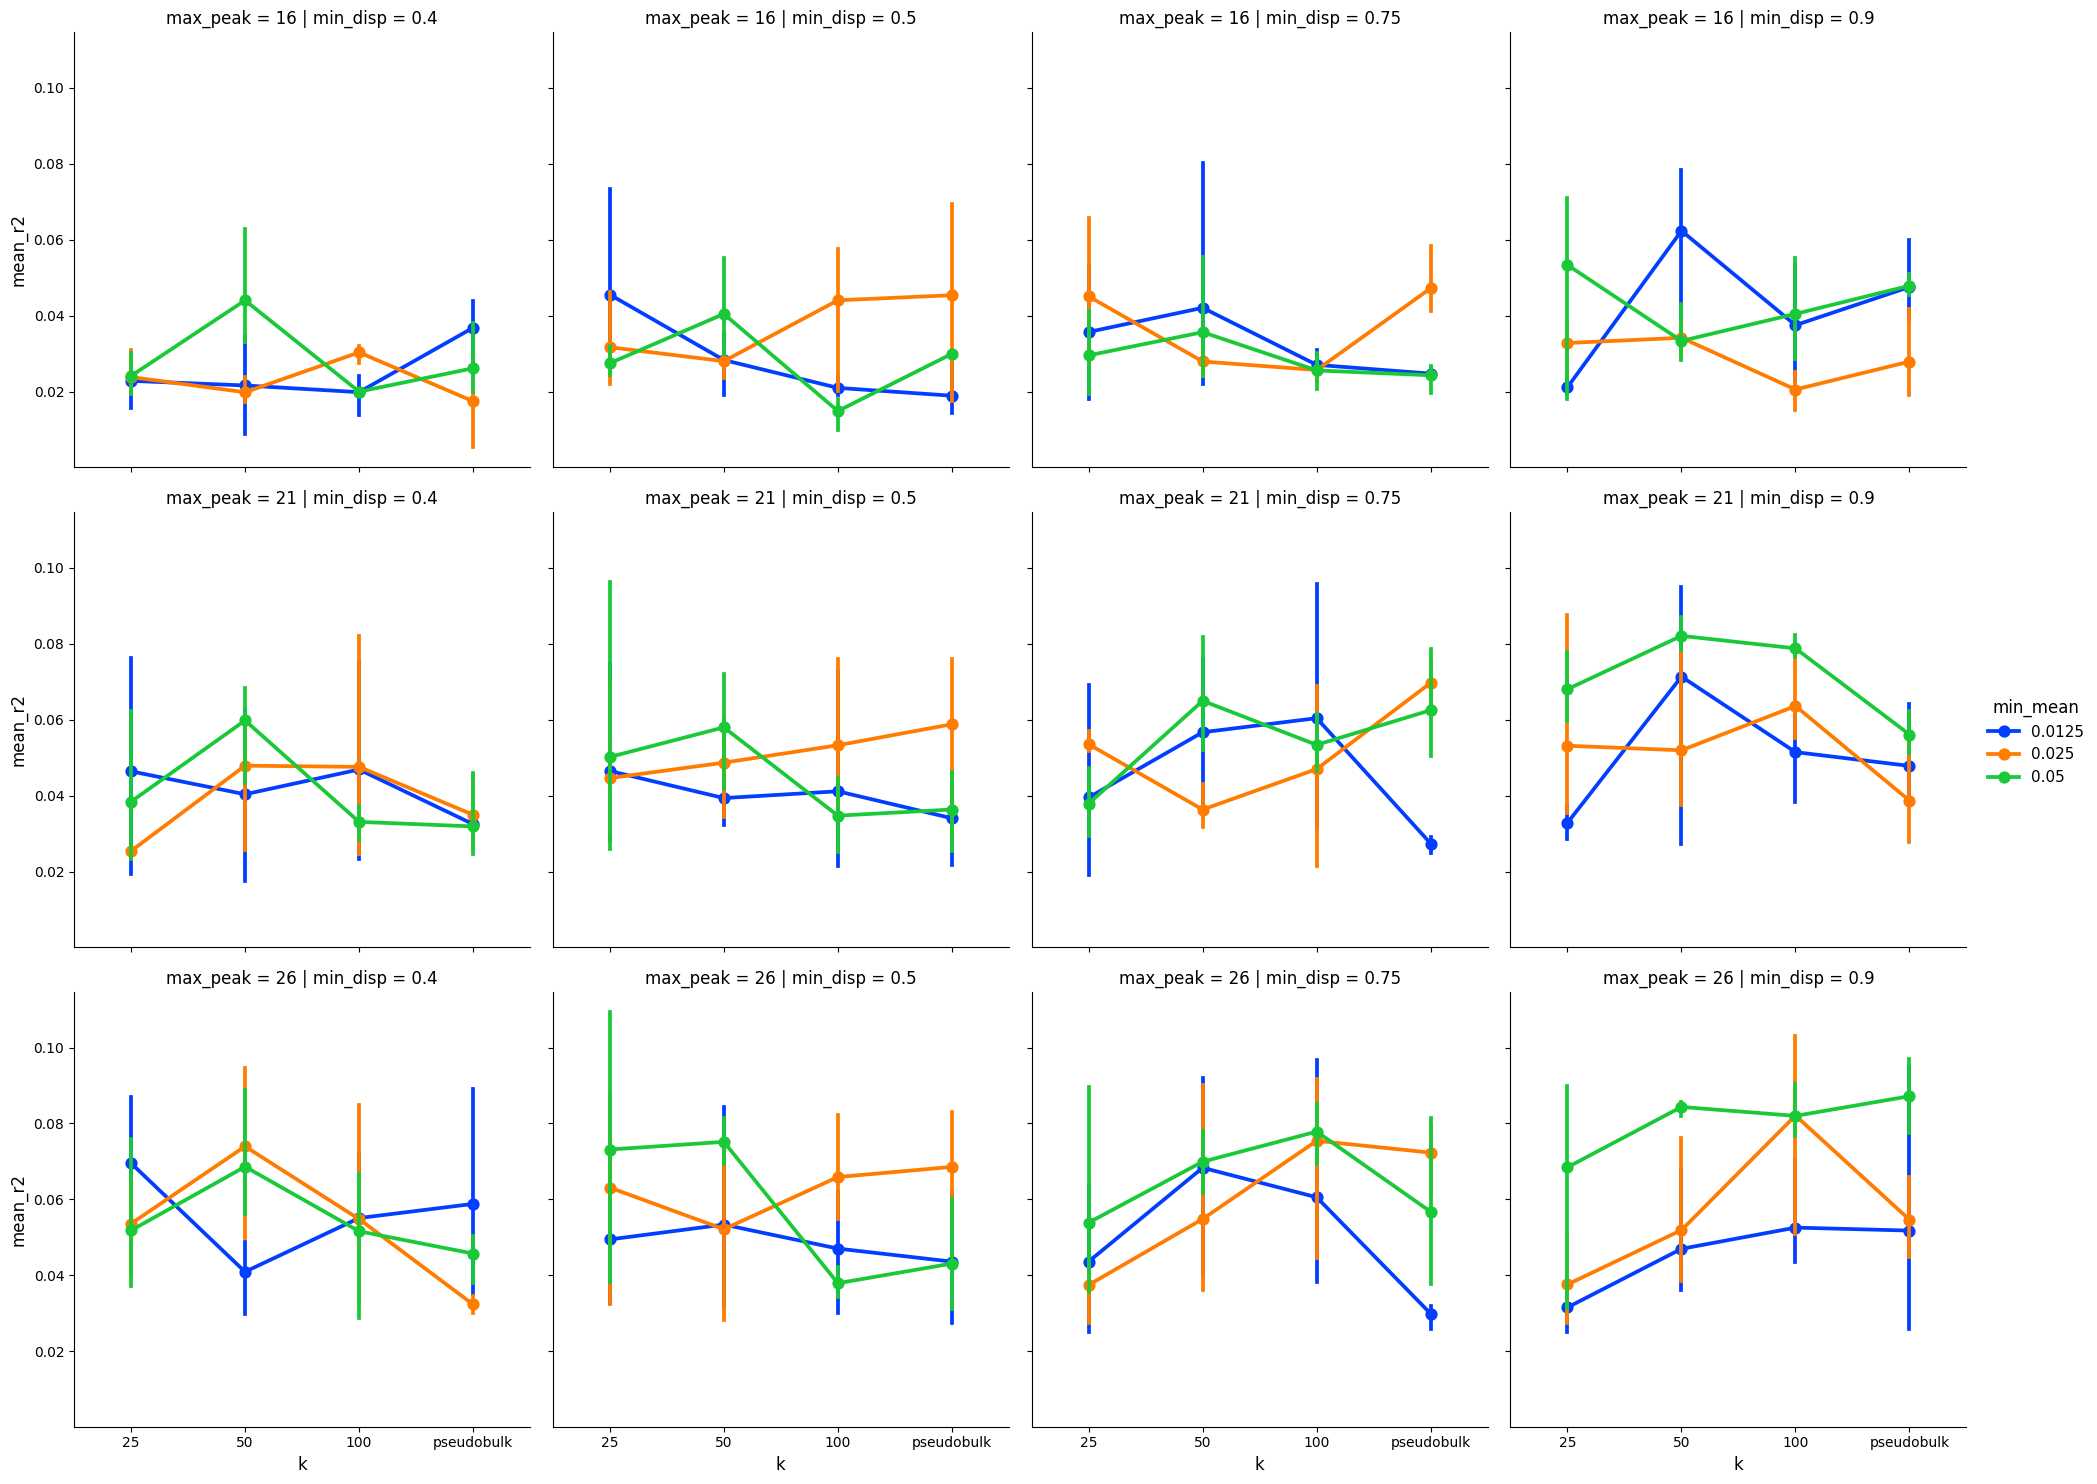

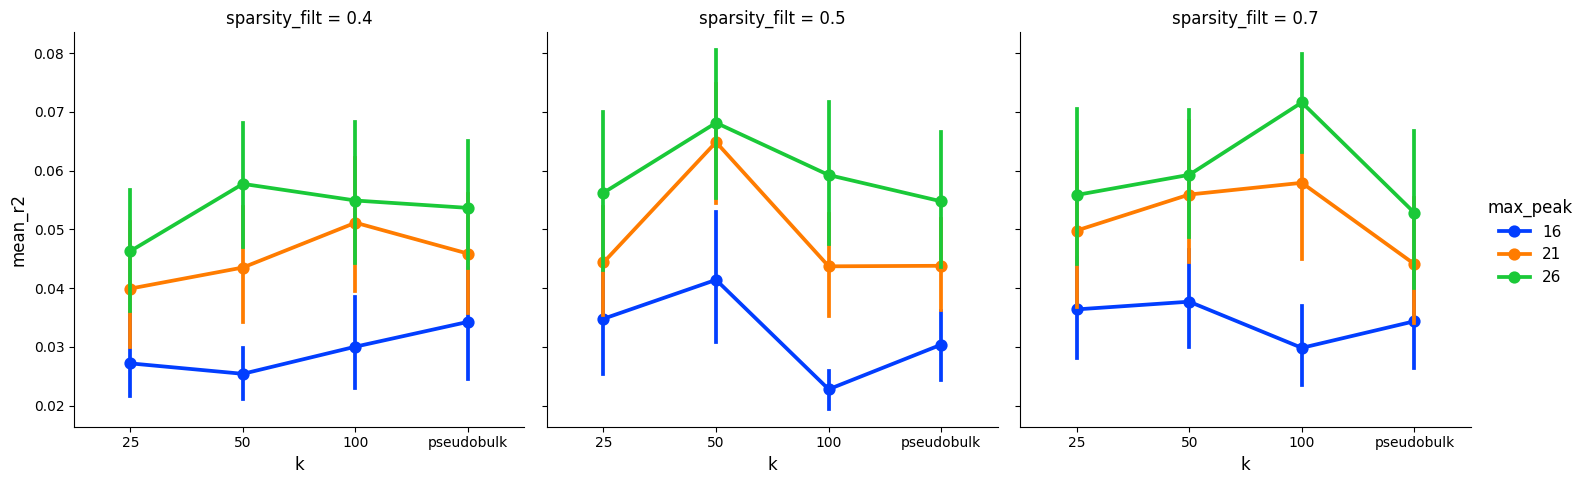

In [4]:
# Cat plot
# Convert k to a categorical type with a specific order
custom_order = ["25", "50", '100', "pseudobulk"]
merged_df["k"] = pd.Categorical(merged_df["k"], categories=custom_order, ordered=True)

# Create the plot with the custom order
sns.catplot(
    data=merged_df,
    x="k",
    y="mean_r2",
    hue="min_mean",
    col="min_disp",
    kind="point",
    row='max_peak',
    palette="bright",
    order=custom_order
)

plt.show()

# Create the plot with the custom order
sns.catplot(
    data=merged_df,
    x="k",
    y="mean_r2",
    hue="max_peak",
    col="sparsity_filt",
    kind="point",
    palette="bright",
    order=custom_order
)

plt.show()

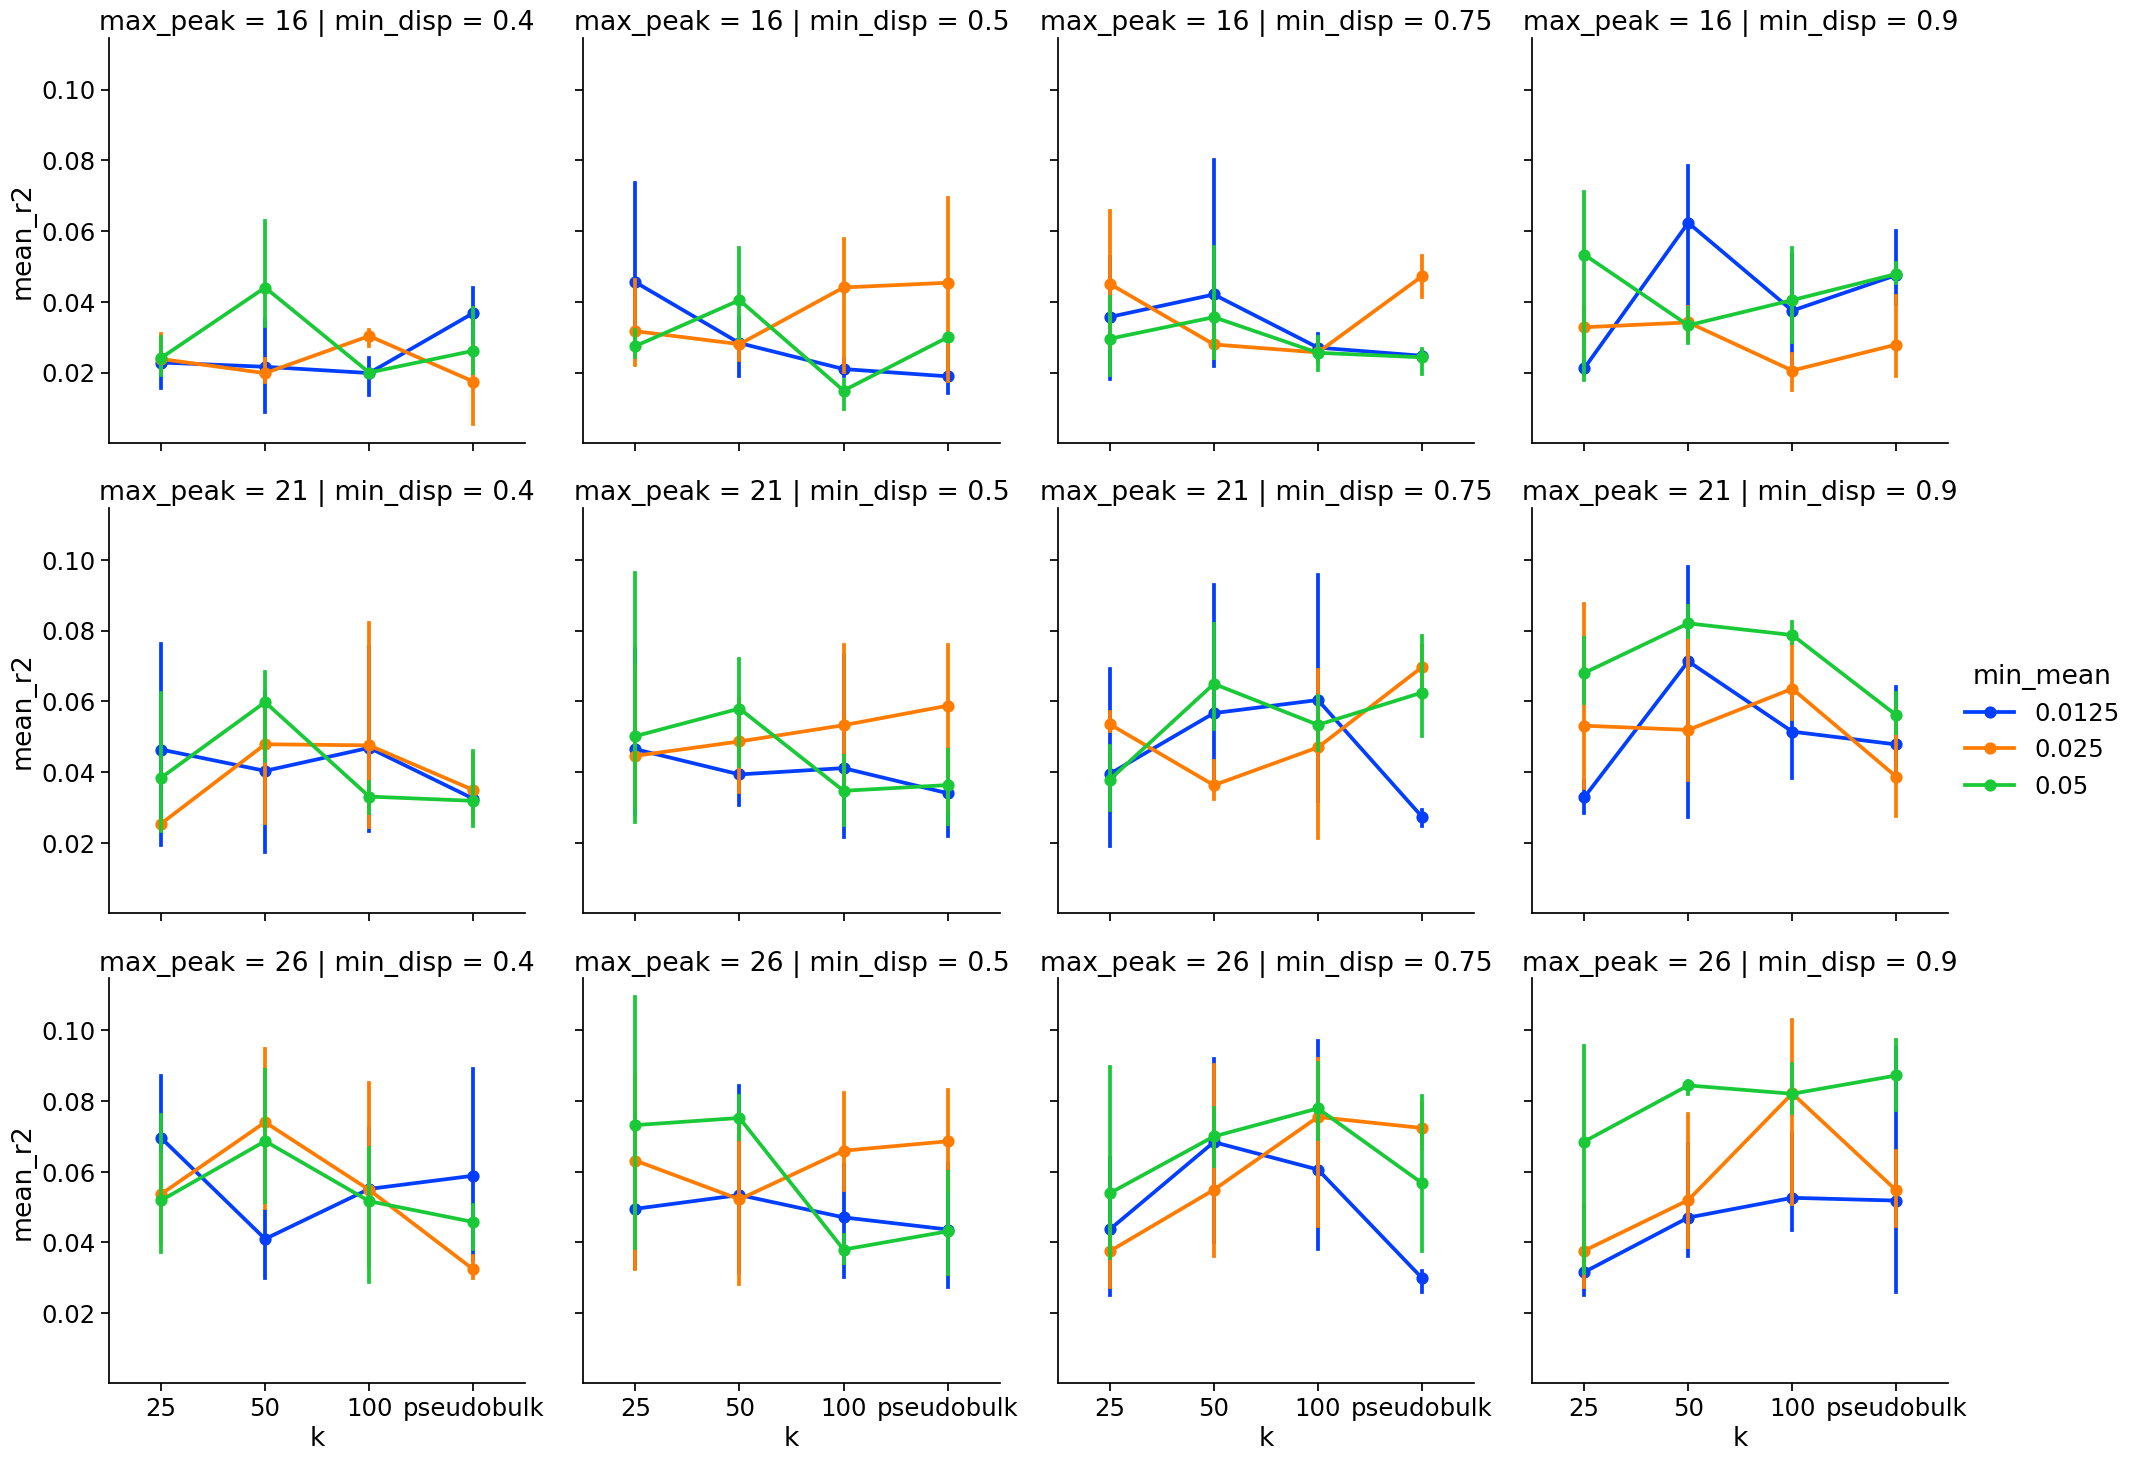

In [5]:
# Cat plot for sparsity
# Set global font scale
sns.set_context("notebook", font_scale=1.6)  # Try 2.0 if you want it even bigger

# Create the plot
g = sns.catplot(
    data=merged_df,
    x="k",
    y="mean_r2",
    hue="min_mean",
    col="min_disp",
    kind="point",
    row="max_peak",
    palette="bright",
    order=custom_order
)

plt.show()

C:\Users\gabri\AppData\Local\Temp\ipykernel_11648\3550803428.py:26: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


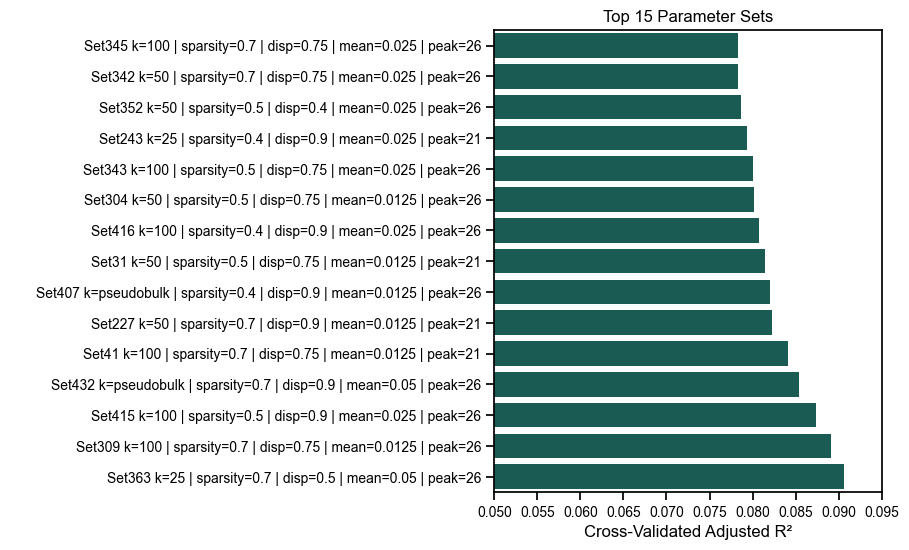

In [94]:
# Barplot with top sets NEW
top_sets = merged_df.sort_values("mean_adjr2", ascending=False).head(15).reset_index()
top_sets["param_label"] = (
    top_sets['SetID'].astype(str) +
    " k=" + top_sets["k"].astype(str) +
    " | sparsity=" + top_sets["sparsity_filt"].astype(str) +
    " | disp=" + top_sets["min_disp"].astype(str) +
    " | mean=" + top_sets["min_mean"].astype(str) +
    " | peak=" + top_sets["max_peak"].astype(str)
)

top_sets["param_label"] = pd.Categorical(top_sets["param_label"], categories=top_sets["param_label"][::-1], ordered=True)

plt.figure(figsize=(5, 6))
ax = sns.barplot(data=top_sets, y="param_label", x="mean_adjr2", color='#0F665C')
ax.set_xlim(0.05, 0.095)
# Increase font sizes here
plt.xlabel("Cross-Validated Adjusted R²")
plt.ylabel(" ", fontsize=16)
plt.title("Top 15 Parameter Sets")

# Increase tick label sizes
#plt.xticks(fontsize=16)
#plt.yticks(fontsize=16)
#plt.savefig(os.path.join(out_dir, 'TopParams.pdf'))
plt.tight_layout()
plt.show()

# Param summary plots

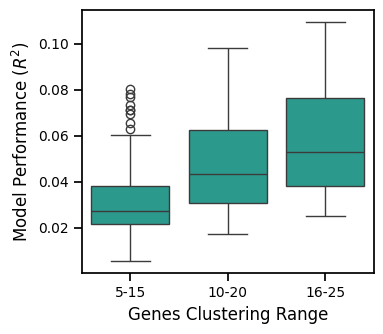

In [105]:
sns.boxplot(data=merged_df, 
            x=merged_df['max_peak'].map({16: '5-15', 21: '10-20', 26:'16-25'}), 
            y=merged_df['mean_r2'],
            order=['5-15', '10-20', '16-25'],
            color='#1AAB9B'
            )
plt.xlabel('Genes Clustering Range')
plt.ylabel(r'Model Performance ($R^{2}$)')
plt.tight_layout()
plt.savefig(os.path.join(out_dir, 'performance_geneclust.pdf'))

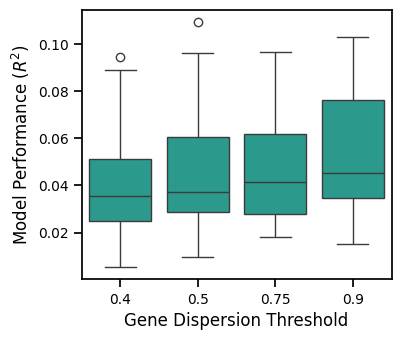

In [106]:
sns.boxplot(data=merged_df, x=merged_df['min_disp'], y=merged_df['mean_r2'], color='#1AAB9B')
plt.xlabel('Gene Dispersion Threshold')
plt.ylabel(r'Model Performance ($R^{2}$)')
plt.savefig(os.path.join(out_dir, 'performance_genedisp.pdf'))

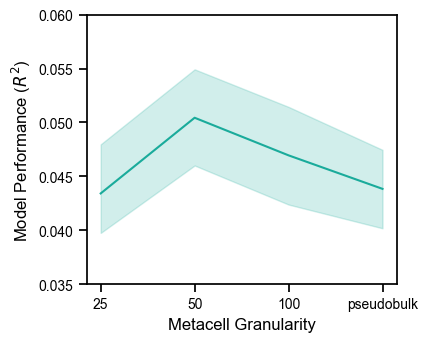

In [93]:
sns.lineplot(data=merged_df, x=merged_df['k'], y=merged_df['mean_r2'], color='#1AAB9B')
plt.xlabel('Metacell Granularity')
plt.ylabel(r'Model Performance ($R^{2}$)')
plt.ylim(0.035, 0.06)
plt.savefig(os.path.join(out_dir, 'performance_metacels.pdf'))

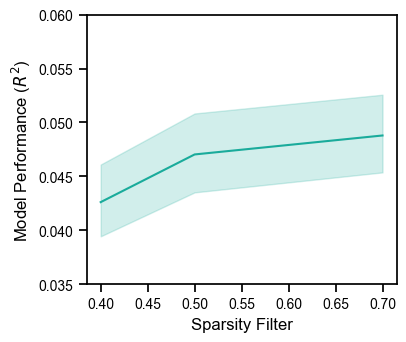

In [92]:
sns.lineplot(data=merged_df, x=merged_df['sparsity_filt'], y=merged_df['mean_r2'], color='#1AAB9B')
plt.xlabel('Sparsity Filter')
plt.ylabel(r'Model Performance ($R^{2}$)')
plt.ylim(0.035, 0.06)
plt.savefig(os.path.join(out_dir, 'performance_sparsfilt.pdf'))

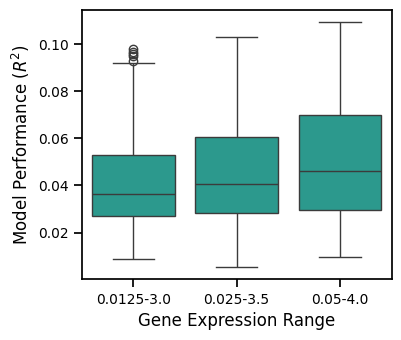

In [119]:
sns.boxplot(data=merged_df, 
            x=merged_df['min_mean'].map({0.0125: '0.0125-3.0', 0.025: '0.025-3.5', 0.05:'0.05-4.0'}), 
            y=merged_df['mean_r2'], color='#1AAB9B')


plt.xlabel('Gene Expression Range')
plt.ylabel(r'Model Performance ($R^{2}$)')

plt.savefig(os.path.join(out_dir, 'performance_geneexprrange.pdf'))